In [15]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

plt.rcParams["figure.figsize"] = (8,6)
plt.rcParams["font.size"] = 12


In [16]:
# Massive MIMO dimensions

M = 64      # BS antennas
K = 8       # Users

num_trials = 1000

snr_db = np.arange(-10, 21, 2)

ber_mrc = []
ber_zf = []
ber_mmse = []

se_mrc = []
se_zf = []
se_mmse = []

ee_mrc = []
ee_zf = []
ee_mmse = []

In [17]:
def qpsk_mod(bits):

    bits = bits.reshape(-1,2)

    symbols = (
        (2*bits[:,0]-1)
        + 1j*(2*bits[:,1]-1)
    )

    return symbols/np.sqrt(2)

In [18]:
def qpsk_demod(symbols):

    bits = np.zeros((len(symbols),2))

    bits[:,0] = np.real(symbols) > 0
    bits[:,1] = np.imag(symbols) > 0

    return bits.astype(int).reshape(-1)

In [19]:
def generate_rayleigh_channel(M,K):

    H = (
        np.random.randn(M,K)
        + 1j*np.random.randn(M,K)
    ) / np.sqrt(2)

    return H

In [20]:
def estimate_channel(H,noise_var):

    estimation_noise = (
        np.random.randn(*H.shape)
        + 1j*np.random.randn(*H.shape)
    ) * np.sqrt(noise_var/2)

    H_est = H + estimation_noise

    return H_est

In [21]:
def mrc_detector(H_est,y):

    W = H_est.conj().T

    x_hat = W @ y

    return x_hat

In [22]:
def zf_detector(H_est,y):

    W = np.linalg.inv(
        H_est.conj().T @ H_est
    ) @ H_est.conj().T

    x_hat = W @ y

    return x_hat

In [23]:
def mmse_detector(H_est,y,noise_var):

    K = H_est.shape[1]

    W = np.linalg.inv(
        H_est.conj().T @ H_est
        + noise_var*np.eye(K)
    ) @ H_est.conj().T

    x_hat = W @ y

    return x_hat

In [11]:
for snr_db_value in snr_db:

    snr_linear = 10**(snr_db_value/10)

    noise_var = 1/snr_linear

    errors_mrc = 0
    errors_zf = 0
    errors_mmse = 0

    total_bits = 0

    rate_mrc = 0
    rate_zf = 0
    rate_mmse = 0

    for trial in range(num_trials):

        #################################
        # Channel
        #################################

        H = generate_rayleigh_channel(
            M,
            K
        )

        H_est = estimate_channel(
            H,
            noise_var
        )

        #################################
        # User Data
        #################################

        bits = np.random.randint(
            0,
            2,
            2*K
        )

        x = qpsk_mod(bits)

        #################################
        # AWGN
        #################################

        noise = (
            np.random.randn(M)
            + 1j*np.random.randn(M)
        ) * np.sqrt(noise_var/2)

        #################################
        # Received Signal
        #################################

        y = H @ x + noise

        #################################
        # MRC
        #################################

        xhat_mrc = mrc_detector(
            H_est,
            y
        )

        bits_hat = qpsk_demod(
            xhat_mrc
        )

        errors_mrc += np.sum(
            bits != bits_hat[:len(bits)]
        )

        #################################
        # ZF
        #################################

        xhat_zf = zf_detector(
            H_est,
            y
        )

        bits_hat = qpsk_demod(
            xhat_zf
        )

        errors_zf += np.sum(
            bits != bits_hat
        )

        #################################
        # MMSE
        #################################

        xhat_mmse = mmse_detector(
            H_est,
            y,
            noise_var
        )

        bits_hat = qpsk_demod(
            xhat_mmse
        )

        errors_mmse += np.sum(
            bits != bits_hat
        )

        total_bits += len(bits)

        #################################
        # Spectral Efficiency
        #################################

        for k in range(K):

            hk = H[:,k]

            gain = np.linalg.norm(hk)**2

            sinr_mrc = snr_linear*gain/K

            sinr_zf = snr_linear*gain

            sinr_mmse = snr_linear*gain

            rate_mrc += np.log2(
                1+sinr_mrc
            )

            rate_zf += np.log2(
                1+sinr_zf
            )

            rate_mmse += np.log2(
                1+sinr_mmse
            )

    ber_mrc.append(
        errors_mrc/total_bits
    )

    ber_zf.append(
        errors_zf/total_bits
    )

    ber_mmse.append(
        errors_mmse/total_bits
    )

    se_mrc.append(
        rate_mrc/num_trials
    )

    se_zf.append(
        rate_zf/num_trials
    )

    se_mmse.append(
        rate_mmse/num_trials
    )

    power_consumption = 10

    ee_mrc.append(
        se_mrc[-1]/power_consumption
    )

    ee_zf.append(
        se_zf[-1]/power_consumption
    )

    ee_mmse.append(
        se_mmse[-1]/power_consumption
    )

    print(
        f"SNR = {snr_db_value} dB completed"
    )

SNR = -10 dB completed
SNR = -8 dB completed
SNR = -6 dB completed
SNR = -4 dB completed
SNR = -2 dB completed
SNR = 0 dB completed
SNR = 2 dB completed
SNR = 4 dB completed
SNR = 6 dB completed
SNR = 8 dB completed
SNR = 10 dB completed
SNR = 12 dB completed
SNR = 14 dB completed
SNR = 16 dB completed
SNR = 18 dB completed
SNR = 20 dB completed


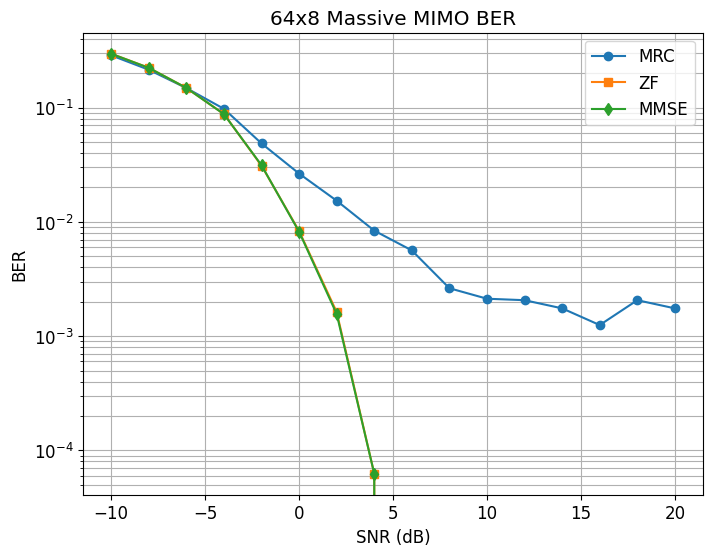

In [12]:
plt.figure()

plt.semilogy(
    snr_db,
    ber_mrc,
    'o-',
    label='MRC'
)

plt.semilogy(
    snr_db,
    ber_zf,
    's-',
    label='ZF'
)

plt.semilogy(
    snr_db,
    ber_mmse,
    'd-',
    label='MMSE'
)

plt.grid(True,which='both')

plt.xlabel("SNR (dB)")
plt.ylabel("BER")

plt.title(
    "64x8 Massive MIMO BER"
)

plt.legend()

plt.show()

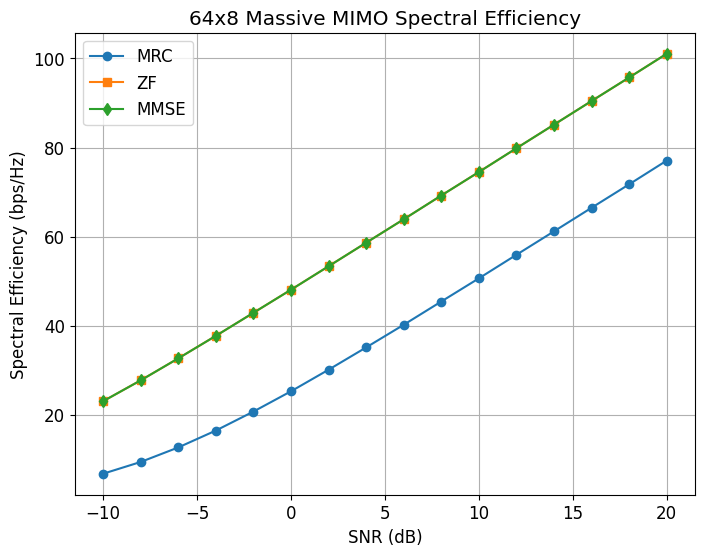

In [13]:
plt.figure()

plt.plot(
    snr_db,
    se_mrc,
    'o-',
    label='MRC'
)

plt.plot(
    snr_db,
    se_zf,
    's-',
    label='ZF'
)

plt.plot(
    snr_db,
    se_mmse,
    'd-',
    label='MMSE'
)

plt.grid()

plt.xlabel("SNR (dB)")
plt.ylabel("Spectral Efficiency (bps/Hz)")

plt.title(
    "64x8 Massive MIMO Spectral Efficiency"
)

plt.legend()

plt.show()

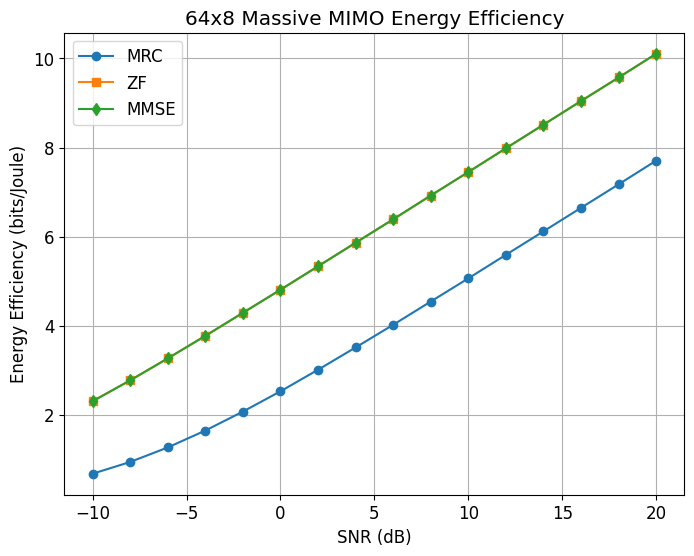

In [14]:
plt.figure()

plt.plot(
    snr_db,
    ee_mrc,
    'o-',
    label='MRC'
)

plt.plot(
    snr_db,
    ee_zf,
    's-',
    label='ZF'
)

plt.plot(
    snr_db,
    ee_mmse,
    'd-',
    label='MMSE'
)

plt.grid()

plt.xlabel("SNR (dB)")
plt.ylabel("Energy Efficiency (bits/Joule)")

plt.title(
    "64x8 Massive MIMO Energy Efficiency"
)

plt.legend()

plt.show()